# 02 — Análise exploratória: perguntas P1–P6

Cada seção responde a uma pergunta de pesquisa do pré-projeto com um gráfico (`src/analise/graficos.py`) e uma tabela/estatística (`src/analise/estatistica.py`).

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import pandas as pd
from src import config
from src.analise.estilo import aplicar_estilo_matplotlib

aplicar_estilo_matplotlib()
pd.set_option("display.max_columns", 50)

In [2]:
from src.analise import estatistica, graficos
from src.pipeline import carregar_base

df = carregar_base()
df[["data", "preco_cafe", "preco_soja", "dolar", "chuva_90d", "temp_min_30d"]].describe()

,data,preco_cafe,preco_soja,dolar,chuva_90d,temp_min_30d
count,1723,1723.000000,1723.000000,1716.000000,1654.000000,1691.000000
mean,2023-06-08 12:00:25.072547840,1294.810238,148.887353,5.266104,239.476393,12.938916
min,2020-01-02 00:00:00,452.940000,84.730000,4.021300,15.996667,4.433333
25%,2021-09-20 12:00:00,838.320000,133.550000,5.061175,65.685833,10.250000
50%,2023-06-09 00:00:00,1241.310000,142.940000,5.246800,207.530000,13.293333
75%,2025-02-22 12:00:00,1619.640000,169.855000,5.477225,369.240000,16.378333
max,2026-11-12 00:00:00,2769.450000,207.140000,6.208600,761.383333,18.073333
std,NaN,572.389484,25.422871,0.334310,188.634395,3.512868


## P1. Como os preços evoluíram entre 2020 e 2026?

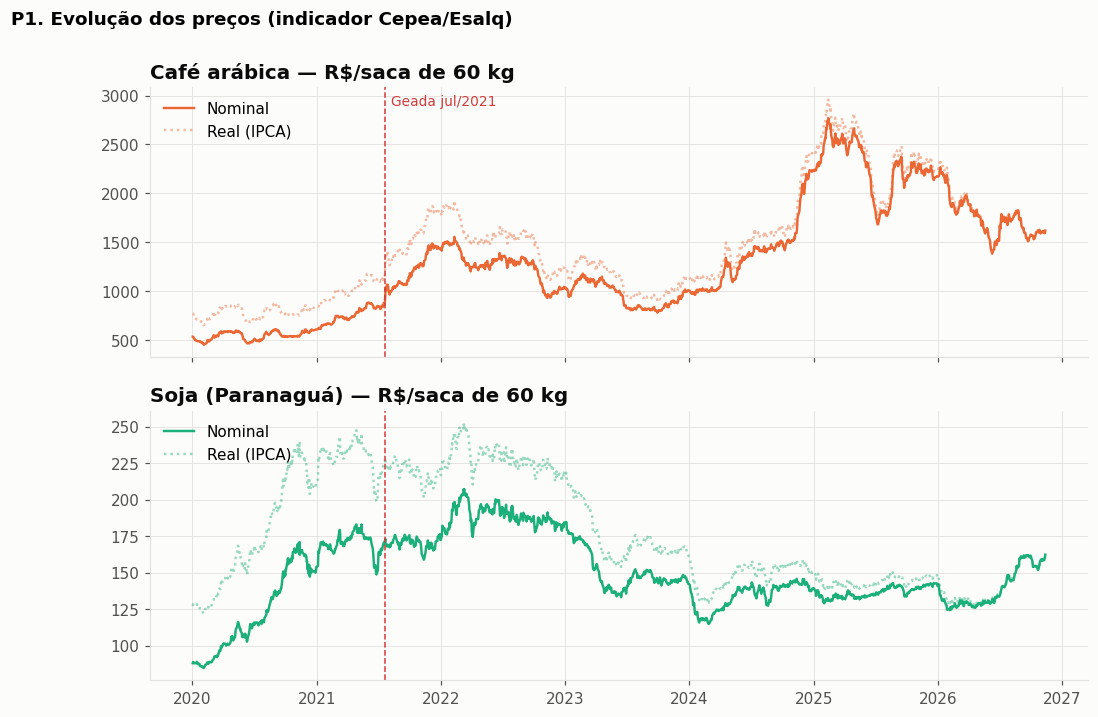

In [3]:
graficos.p1_evolucao(df);

In [4]:
estatistica.resumo_evolucao(df)

,ano,mean,min,max,variacao_ano_pct,produto
0,2020,543.44,452.94,610.57,13.52,cafe
1,2021,965.88,611.28,1487.58,132.48,cafe
2,2022,1260.07,930.62,1555.19,-26.63,cafe
3,2023,953.38,779.90,1179.20,-2.11,cafe
4,2024,1375.91,962.99,2236.76,122.05,cafe
5,2025,2270.39,1682.70,2769.45,-3.00,cafe
6,2026,1750.95,1383.57,2266.21,-25.44,cafe
7,2020,121.48,84.73,170.97,74.73,soja
8,2021,170.10,148.74,183.02,11.40,soja
9,2022,188.87,174.46,207.14,5.44,soja


## P2. Existe sazonalidade (safra × entressafra)?
Preço real dividido pela média do próprio ano (remove a tendência). Kruskal-Wallis testa se as distribuições diferem entre meses.

10:07:04 INFO    matplotlib.category: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


10:07:04 INFO    matplotlib.category: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


10:07:05 INFO    matplotlib.category: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


10:07:05 INFO    matplotlib.category: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


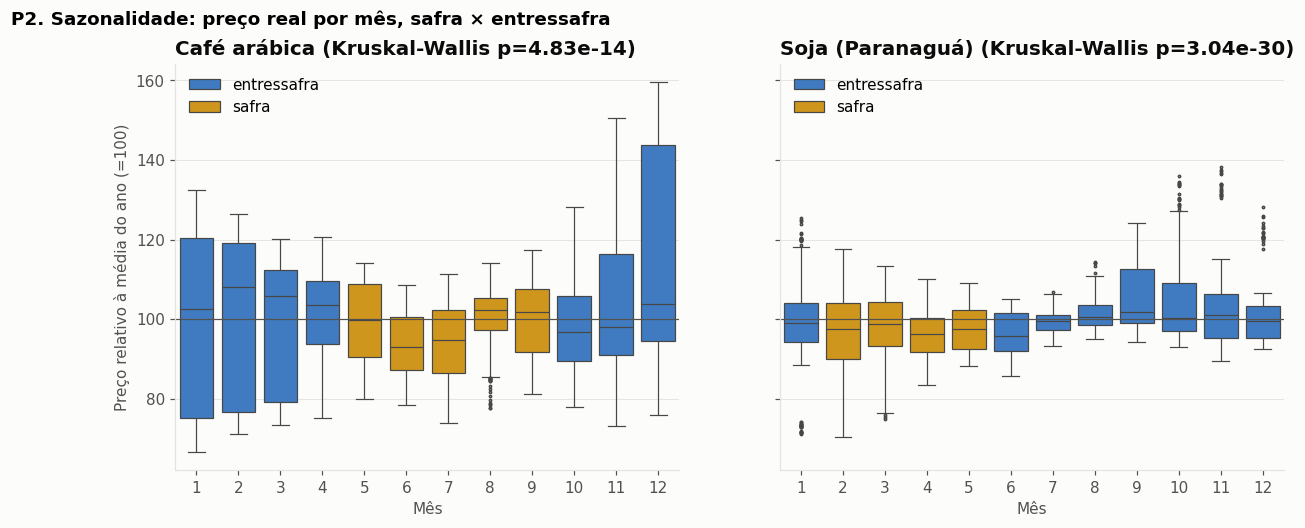

In [5]:
graficos.p2_sazonalidade(df);

In [6]:
for p in config.COMMODITIES:
    tabela, pval = estatistica.sazonalidade(df, p)
    print(p, "Kruskal-Wallis p =", f"{pval:.3g}")
    display(tabela)

cafe Kruskal-Wallis p = 4.83e-14


,mes,mean,median,std,periodo
0,1,99.75,102.65,20.71,entressafra
1,2,100.82,108.09,19.76,entressafra
2,3,99.82,105.86,15.60,entressafra
3,4,100.68,103.66,12.48,entressafra
4,5,98.86,99.75,9.94,safra
5,6,93.79,92.99,7.61,safra
6,7,93.92,94.82,9.66,safra
7,8,99.37,102.36,9.01,safra
8,9,99.57,101.83,9.33,safra
9,10,98.72,96.87,12.30,entressafra


soja Kruskal-Wallis p = 3.04e-30


,mes,mean,median,std,periodo
0,1,98.37,99.01,13.47,entressafra
1,2,96.46,97.42,12.69,safra
2,3,97.55,98.66,10.03,safra
3,4,96.08,96.30,6.61,safra
4,5,97.58,97.46,5.43,safra
5,6,96.55,95.87,5.40,entressafra
6,7,99.54,99.51,2.90,entressafra
7,8,101.66,100.55,4.37,entressafra
8,9,104.44,101.83,7.49,entressafra
9,10,104.94,100.35,11.57,entressafra


## P3. Os preços acompanham o dólar? Com que defasagem?
Índice base 100 (um único eixo, em vez de eixo duplo) e correlação cruzada entre as **variações** do preço e do dólar defasado.

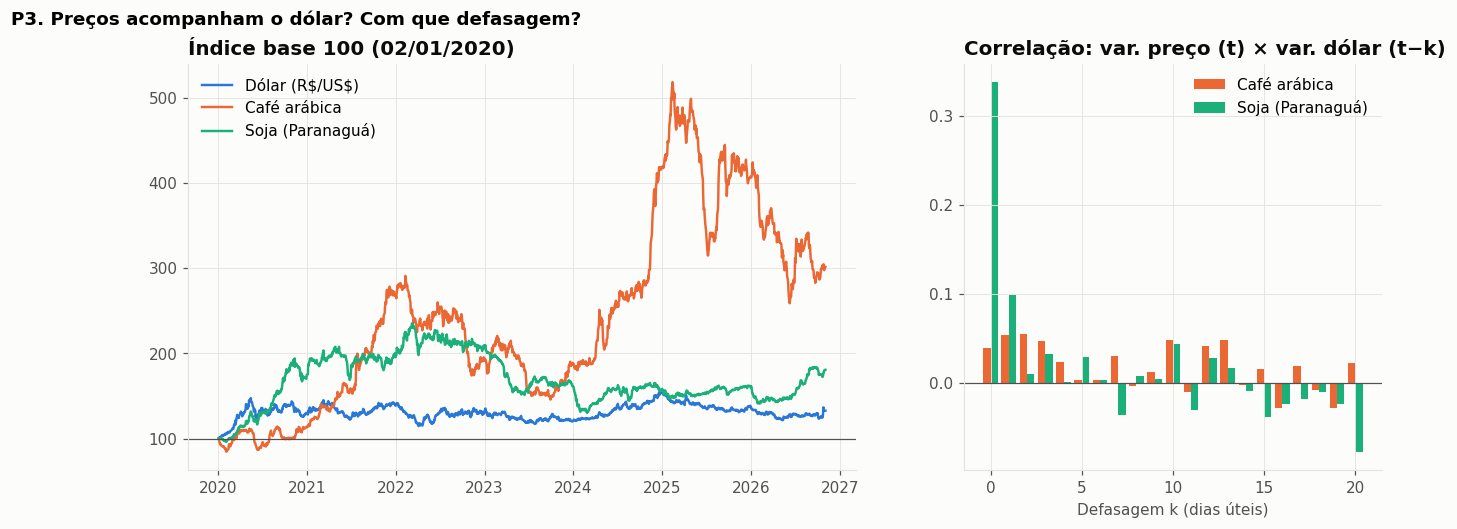

In [7]:
graficos.p3_dolar(df);

In [8]:
for p in config.COMMODITIES:
    cc = estatistica.correlacao_cruzada(df, p)
    print(p, "- defasagem de maior correlação:", cc.loc[cc["correlacao"].abs().idxmax()].to_dict())
pd.DataFrame([estatistica.repasse_cambial(df, p) for p in config.COMMODITIES])

cafe - defasagem de maior correlação: {'defasagem': 2.0, 'correlacao': 0.05432196624167881, 'p_valor': 0.024472283394814536, 'n': 1715.0}
soja - defasagem de maior correlação: {'defasagem': 0.0, 'correlacao': 0.33781936888204933, 'p_valor': 4.788064642749819e-47, 'n': 1715.0}


,produto,elasticidade,r2,p_valor,meses
0,cafe,0.560554,0.050638,0.042095,82
1,soja,0.517849,0.130256,0.000865,82


## P4. Pouca chuva ou temperaturas extremas são seguidas de alta no café?

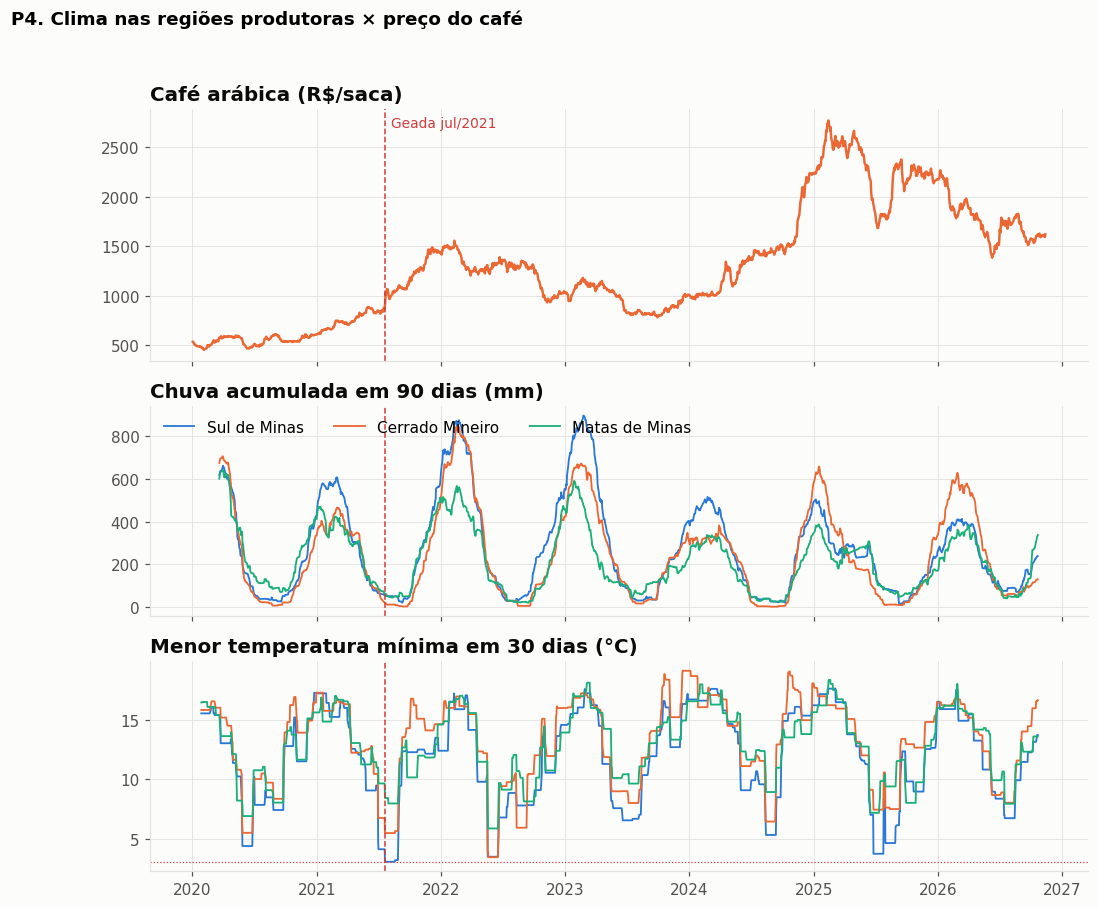

In [9]:
graficos.p4_clima(df);

In [10]:
estatistica.clima_vs_preco_futuro(df, 'cafe').head(10)

,variavel_clima,spearman,p_valor,n
11,temp_max_30d_cerrado_mineiro,0.343209,1.251947e-46,1643
9,chuva_90d_cerrado_mineiro,-0.264723,3.689484e-27,1606
7,temp_max_30d_sul_de_minas,0.238600,1.061028e-22,1643
3,temp_max_30d,0.236295,2.774020e-22,1643
1,chuva_90d,-0.197382,1.433322e-15,1606
5,chuva_90d_sul_de_minas,-0.178099,6.511721e-13,1606
8,chuva_30d_cerrado_mineiro,-0.140335,1.114682e-08,1643
13,chuva_90d_matas_de_minas,-0.109713,1.049923e-05,1606
15,temp_max_30d_matas_de_minas,0.100246,4.690285e-05,1643
0,chuva_30d,-0.097456,7.600069e-05,1643


## P5. Impacto da geada de julho de 2021
A soja, pouco exposta ao clima de MG, funciona como grupo de controle.

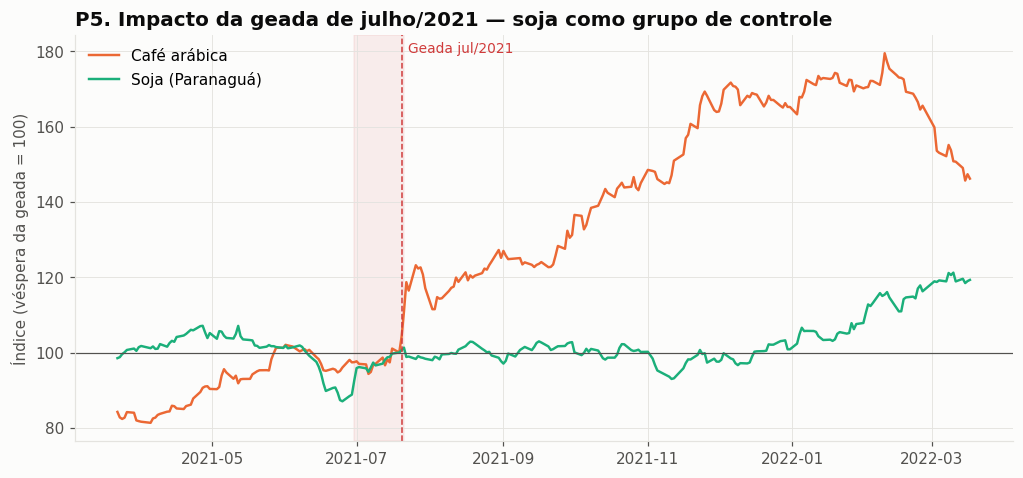

In [11]:
graficos.p5_geada(df);

In [12]:
estatistica.impacto_geada(df)

,produto,media_30d_antes,media_30d_depois,var_30d_pct,maximo_30d,media_90d_depois,var_90d_pct,maximo_90d,media_180d_depois,var_180d_pct,maximo_180d
0,cafe,839.98,1014.46,20.8,1067.27,1077.75,28.3,1242.78,1233.84,46.9,1502.91
1,soja,161.10,170.53,5.9,175.83,171.25,6.3,175.95,170.94,6.1,182.14


## P6. Qual commodity é mais sensível ao clima e qual ao câmbio?

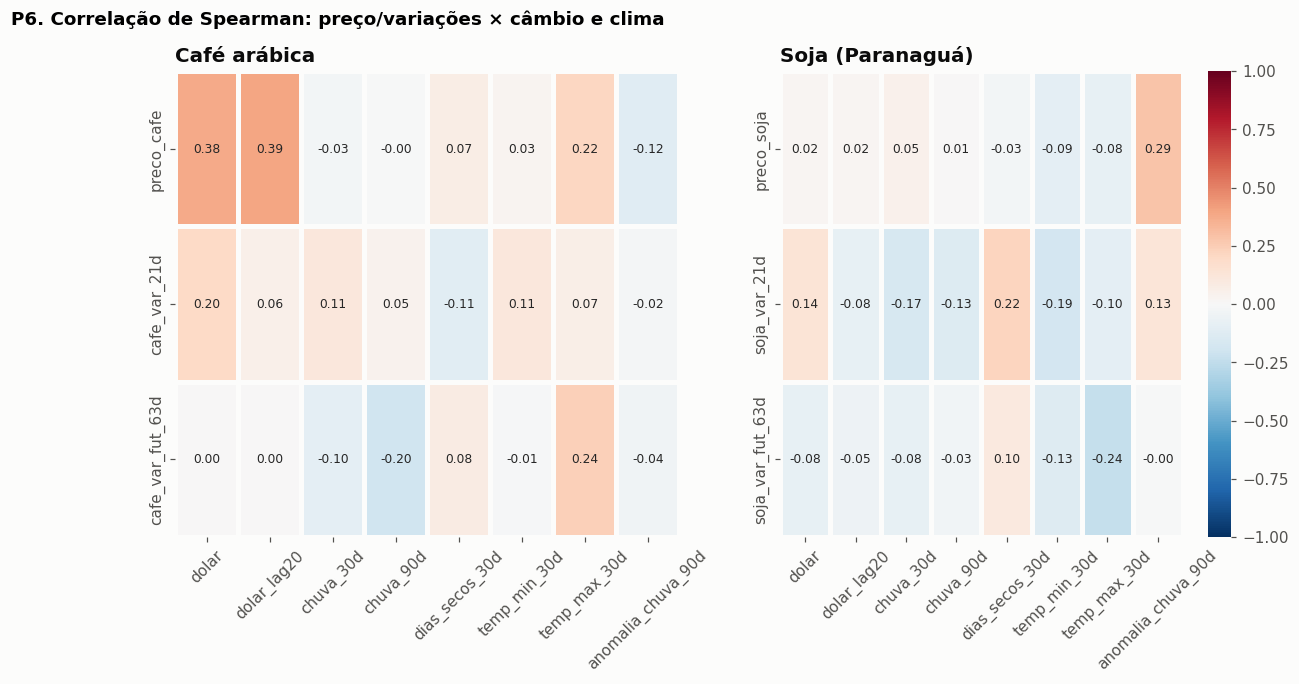

In [13]:
graficos.p6_correlacoes(df);

In [14]:
estatistica.sensibilidade(df)

,produto,corr_diaria_dolar_t0,elasticidade_cambio_mensal,r2_cambio_mensal,max_abs_spearman_clima,variavel_clima_mais_associada
0,cafe,0.039,0.561,0.051,0.343,temp_max_30d_cerrado_mineiro
1,soja,0.338,0.518,0.130,0.303,temp_max_30d_matas_de_minas


> Lembrete: as relações indicam **correlação**, não causalidade — estoques mundiais, demanda internacional e produção de outros países não estão no estudo.